In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import pearsonr, zscore
import scienceplots
plt.style.use(['science', 'nature'])
import seaborn as sns
from matplotlib.colors import ListedColormap
colors = {
    "grey":   "#4d4d4d",  # neutral line/axis color
}
# NMDA sequential (red)
nmda_cmap = LinearSegmentedColormap.from_list( "nmda_seq", ["#fee0d2", "#f89f84", "#de2d26"], N=256)

In [2]:
# How much excitation / inhibition the nodes receive from other nodes
W_E = np.load('../../../data/processed/schaefer200_W_E_SC_SLN.npy') # Matrix of SC * SLN
W_I = np.load('../../../data/processed/schaefer200_W_I_SC_SLN.npy') # Matrix of SC * (1 - SLN)
E_to_source = np.zeros(100)
I_to_source = np.zeros(100)
for index, row in enumerate(W_E): # Each row represents a target, and each column a source
    E_to_source[index] = np.sum(row)
for index, row in enumerate(W_I): # Each row represents a target, and each column a source
    I_to_source[index] = np.sum(row)
E_minus_I_receive = E_to_source - I_to_source # Net excitation
# Area names, remove the 7Networks_LH_ prefix from names
area_names = pd.read_csv('../../../data/processed/schaefer200_LH_area_names.csv')['Area_name'].tolist()
for index, name in enumerate(area_names):
    area_names[index] = name.replace('7Networks_LH_', '')
    
# Load hierarchy for left hemisphere
hierarchies = pd.read_csv('../../../data/processed/schaefer200_LH_hierarchy.csv')['Hierarchy_val'].tolist()

W = np.array(pd.read_csv('../../../data/processed/schaefer200_LH_sc.csv')) # DTI derived normalized structural connectivity matrix
N = W.shape[0] # Number of areas in the network
degree = W.sum(axis=1) # Connectivity degree based on the structural connectivity matrix

# Load NMDA receptor density based on autoradiography (initially nan values were filled through the relationship with hierarchy)
nmda_rd = pd.read_csv('../../../data/processed/schaefer200_LH_NMDA_rd.csv')['NMDA_rd']

# Persistent areas and delay firing rates across network
persistent_areas = np.load('../results/main_task/persistent_areas_G083_alpha134.npy')
delay_fr = np.load('../results/main_task/delay_FR_G083_alpha134.npy')

# Build dataframe with all the data
dict_network = {'area_names': area_names, 'hierarchy': hierarchies, 'E_to_source': E_to_source,
                'I_to_source': I_to_source, 'E_minus_I_receive': E_minus_I_receive,
                'nmda_rd': nmda_rd, 'delay_fr': delay_fr, 'degree': degree}
network_connectivity = pd.DataFrame(dict_network)

## Plot long-range input to E vs. I and overlay persistent activity nodes

Number of excitation receivers: 53


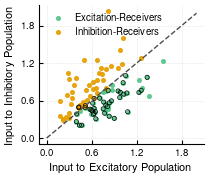

In [3]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})
def excitation_inhibition_receivers(row):
    if row['E_to_source']  - row['I_to_source'] > 0:
        return 'Excitation-Receivers'
    else:
        return 'Inhibition-Receivers'

df_e_vs_i = network_connectivity.copy()
df_e_vs_i['persistent'] = df_e_vs_i['area_names'].isin(persistent_areas)
df_e_vs_i['node_type'] = df_e_vs_i.apply(excitation_inhibition_receivers, axis=1)
print("Number of excitation receivers:", len(df_e_vs_i[df_e_vs_i['node_type'] == 'Excitation-Receivers']))
# Figure 2
fig, ax = plt.subplots(figsize=(2.2, 1.9))
# Boolean masks
mask_exc = df_e_vs_i['E_to_source'] >= df_e_vs_i['I_to_source']
mask_inh = ~mask_exc
# plot excitation-receivers
ax.scatter(
    df_e_vs_i.loc[mask_exc, 'E_to_source'],
    df_e_vs_i.loc[mask_exc, 'I_to_source'],
    c='#56c68a',
    s=7,
    alpha=0.9,
    label='Excitation-Receivers'
)
# plot inhibition-receivers
ax.scatter(
    df_e_vs_i.loc[mask_inh, 'E_to_source'],
    df_e_vs_i.loc[mask_inh, 'I_to_source'],
    c='#e69f00',
    s=7,
    alpha=0.9,
    label='Inhibition-Receivers'
)
ax.plot([0, 2], [0, 2], color=colors['grey'], ls='--', lw=1.0)
ax.set_xlabel('Input to Excitatory Population', )
ax.set_ylabel('Input to Inhibitory Population', )
ax.grid(linestyle=':', alpha=0.5)
ax = plt.gca()
from matplotlib.ticker import MaxNLocator

ax.minorticks_off()
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(4))
ax.grid(which='major', linestyle=':', alpha=0.5)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
leg = ax.legend(loc='best', frameon=False)
frame = leg.get_frame()
frame.set_edgecolor('grey')

persist = df_e_vs_i[df_e_vs_i['persistent'] == True]
ax.scatter(persist['E_to_source'], persist['I_to_source'],
           facecolors='none', edgecolors='black',
           s=9, linewidths=0.5, label='Persistent')

plt.tight_layout()
plt.savefig('../results/main_task/compare_to_data/E_to_source_vs_I_to_source.svg', bbox_inches='tight')
plt.show()
plt.close()

Pearson r = 0.843, p = 4.14e-28
Spearman r = 0.953, p = 1e-52


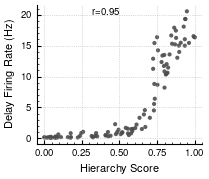

In [6]:
from scipy.stats import spearmanr
# Fit a simple linear trend line
x = network_connectivity['hierarchy']
y = network_connectivity['delay_fr']
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")

r_spearman, p_spearman = spearmanr(x, y)
print(f"Spearman r = {r_spearman:.3f}, p = {p_spearman:.3g}")

fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=9, alpha=0.9, color=colors['grey'], edgecolor='none')
ax.set_xlabel('Hierarchy Score')
ax.set_ylabel('Delay Firing Rate (Hz)')
ax.grid(linestyle=':', alpha=0.9)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
ax.text(
    0.5, 0.98, f"r={r_spearman:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('../results/main_task/compare_to_data/delay_FR_vs_hierarchy.svg', bbox_inches='tight')
plt.show()

Pearson r = -0.163, p = 0.105


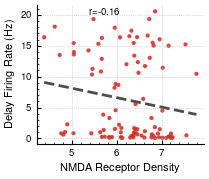

In [5]:
from scipy.stats import spearmanr
# Fit a simple linear trend line
x = network_connectivity['nmda_rd']
y = network_connectivity['delay_fr']
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")


fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=9, alpha=0.9, color='#de2d26', edgecolor='none')
slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color=colors['grey'], linestyle='--', linewidth=2,
         label=f"y = {slope:.2f} x NMDA_rd + ({intercept:.2f})")
ax.set_xlabel('NMDA Receptor Density')
ax.set_ylabel('Delay Firing Rate (Hz)')
ax.grid(linestyle=':', alpha=0.9)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
ax.text(
    0.5, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('../results/main_task/compare_to_data/delay_FR_vs_nmda_rd.svg', bbox_inches='tight')
plt.show()